# 03 複数往復・停止判定・bond上限比較

このNotebookでは、02で完成させたenvironmentベースの2-site DMRGを反復し、**停止可能な基底状態探索**へ接続する。

新しい局所有効Hamiltonianや局所ソルバーは実装しない。学習対象は次の4点である。

1. 左→右passと右→左passを1往復として接続し、更新後のMPSを次の往復へ渡す。
2. 往復間のenergy変化から、停止理由を持つ反復処理を作る。
3. 全残差とenergy分散を使い、energyの安定と固有状態への近さを区別する。
4. 共通初期状態からbond上限だけを変え、停止と表現制約を区別して観察する。

今回扱わないものは、Lanczos／Davidson、matrix-free固有値solver、1-site sweep、長鎖化、性能測定、ニューラルネットワークへの適用である。


## 1. 学習の進め方と依存関係

このNotebookは、同じディレクトリにある`02_environment_two_site_dmrg_sweep_exercises.ipynb`の完成済み実装に依存する。

- 02の局所更新、SVD分割、environment更新、左右passをそのまま再利用する。
- 02が未完成で1往復できない場合、03の依存部分は`SKIP`になる。
- 03のDMRG固有部分は`___`を残している。
- 未回答なら`TODO`または`SKIP`、数値検証を通過した場合だけ`OK`と表示する。
- TODOの直前では目的・変数・数式・検証内容を説明するが、完成したAPI呼び出しは示さない。

このNotebookの穴埋めを始める前に、02をRestart Kernel後にRun Allし、最後まで`OK`になっていることを確認する。


In [1]:
from __future__ import annotations

from contextlib import redirect_stderr, redirect_stdout
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
from dataclasses import dataclass
import io
import json
import math
import sys
from pathlib import Path
from typing import Literal

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display


def find_project_root(start: Path) -> Path:
    """src/nn_compressionを含むプロジェクトルートを返す。"""
    for candidate in (start, *start.parents):
        if (candidate / "src" / "nn_compression").is_dir():
            return candidate
    raise FileNotFoundError("src/nn_compressionを含むプロジェクトルートが見つかりません。")


def load_completed_notebook_namespace(notebook_path: Path) -> dict[str, object]:
    """既存Notebookのコードセルを順番に実行し、定義済み名前空間を返す。"""
    notebook = json.loads(notebook_path.read_text(encoding="utf-8"))
    namespace: dict[str, object] = {"__name__": "__main__"}
    captured_stdout = io.StringIO()
    captured_stderr = io.StringIO()
    original_show = plt.show

    try:
        plt.show = lambda *args, **kwargs: None
        with redirect_stdout(captured_stdout), redirect_stderr(captured_stderr):
            for cell_index, cell in enumerate(notebook["cells"]):
                if cell.get("cell_type") != "code":
                    continue
                source = "".join(cell.get("source", []))
                exec(
                    compile(source, f"{notebook_path.name}:cell_{cell_index}", "exec"),
                    namespace,
                )
    finally:
        plt.show = original_show
        plt.close("all")

    return namespace


PROJECT_ROOT = find_project_root(Path.cwd())
NOTEBOOK_DIRECTORY = PROJECT_ROOT / "notebooks" / "40_dmrg" / "00_fundamentals"
PREVIOUS_NOTEBOOK_PATH = (
    NOTEBOOK_DIRECTORY / "02_environment_two_site_dmrg_sweep_exercises.ipynb"
)

if not PREVIOUS_NOTEBOOK_PATH.is_file():
    raise FileNotFoundError(f"前提Notebookが見つかりません: {PREVIOUS_NOTEBOOK_PATH}")

DMRG02 = load_completed_notebook_namespace(PREVIOUS_NOTEBOOK_PATH)

REQUIRED_NAMES = (
    "ATOL",
    "RTOL",
    "H_DENSE",
    "H_FROM_MPO",
    "MPO_CORES",
    "SWEEP_INITIAL_CORES",
    "LEFT_PASS_RESULT",
    "normalized_energy",
    "mps_mpo_energy",
    "sweep_left_to_right",
    "sweep_right_to_left",
    "tt_canonicality_errors",
    "tt_reconstruct",
    "tt_ranks",
)
missing_names = [name for name in REQUIRED_NAMES if name not in DMRG02]
if missing_names:
    raise RuntimeError(f"02から必要な名前を取得できません: {missing_names}")

DEVICE = DMRG02["DEVICE"]
DTYPE = DMRG02["DTYPE"]
ATOL = float(DMRG02["ATOL"])
RTOL = float(DMRG02["RTOL"])
LENGTH = int(DMRG02["LENGTH"])

MIN_ROUND_TRIPS = 2
MAX_ROUND_TRIPS = 12
ENERGY_TOLERANCE = 1.0e-10
REQUIRED_CONSECUTIVE_STABLE_ROUNDS = 2

# 2は02と同じ強い制約、4は中間、Noneは意図的な切り捨てを行わないcontrol。
BOND_LIMITS: tuple[int | None, ...] = (2, 4, None)

# 各TODOでは右辺の___を実装へ置き換える。
___ = None

print("project root:", PROJECT_ROOT)
print("previous notebook:", PREVIOUS_NOTEBOOK_PATH.name)
print("device / dtype:", DEVICE, DTYPE)


project root: d:\dev\nn-compression-svd-dmrg
previous notebook: 02_environment_two_site_dmrg_sweep_exercises.ipynb
device / dtype: cpu torch.float64


## 2. 02から再利用するAPIと基準問題

03は、02で完成させた次の処理を再利用する。

- `sweep_left_to_right`：現在のMPSを受け取り、左端のペアから右端のペアまで更新する。
- `sweep_right_to_left`：右向きpassの結果を受け取り、右端のペアから左端のペアまで更新する。
- `SweepPassResult.cores`：pass終了後のMPS。次のpassまたは次の往復へ渡す。
- `SweepPassResult.logs`：各局所更新のrank、局所最小energy、discarded weight、局所残差など。
- `mps_mpo_energy`：MPSとMPOの縮約から全energyを計算する。
- `tt_reconstruct`：診断用に小さいMPSから全状態を再構成する。

基準問題、dtype、device、乱数seed、初期MPSは02と同じものを使う。bond上限比較では、この共通初期MPSを条件ごとに複製する。また、共通初期MPSの全内部bond dimensionが、`BOND_LIMITS`から求めた最小の有限上限以下であることを先に検証する。


In [2]:
H_DENSE = DMRG02["H_DENSE"].clone()
H_FROM_MPO = DMRG02["H_FROM_MPO"].clone()
MPO_CORES = [core.clone() for core in DMRG02["MPO_CORES"]]
COMMON_INITIAL_CORES = [core.clone() for core in DMRG02["SWEEP_INITIAL_CORES"]]

normalized_energy = DMRG02["normalized_energy"]
mps_mpo_energy = DMRG02["mps_mpo_energy"]
sweep_left_to_right = DMRG02["sweep_left_to_right"]
sweep_right_to_left = DMRG02["sweep_right_to_left"]
tt_canonicality_errors = DMRG02["tt_canonicality_errors"]
tt_reconstruct = DMRG02["tt_reconstruct"]
tt_ranks = DMRG02["tt_ranks"]

DEPENDENCY_READY = DMRG02["LEFT_PASS_RESULT"] is not None

torch.testing.assert_close(H_FROM_MPO, H_DENSE, atol=ATOL, rtol=RTOL)

initial_state = tt_reconstruct(COMMON_INITIAL_CORES).reshape(-1)
initial_norm_squared = torch.vdot(initial_state, initial_state).real
initial_energy_dense = normalized_energy(initial_state, H_DENSE)
initial_energy_mpo = mps_mpo_energy(COMMON_INITIAL_CORES, MPO_CORES)
exact_ground_energy = torch.linalg.eigvalsh(H_DENSE)[0]
initial_canonicality = tt_canonicality_errors(COMMON_INITIAL_CORES, center=0)
finite_bond_limits = tuple(
    bond_limit for bond_limit in BOND_LIMITS if bond_limit is not None
)
if not finite_bond_limits:
    raise ValueError("BOND_LIMITSには少なくとも1つの有限なbond上限が必要です。")
smallest_finite_bond_limit = min(finite_bond_limits)
initial_internal_bond_dimensions = tuple(
    int(rank) for rank in tt_ranks(COMMON_INITIAL_CORES)[1:-1]
)

torch.testing.assert_close(
    initial_norm_squared,
    initial_norm_squared.new_tensor(1.0),
    atol=ATOL,
    rtol=RTOL,
)
torch.testing.assert_close(
    initial_energy_dense,
    initial_energy_mpo,
    atol=ATOL,
    rtol=RTOL,
)
assert all(error.item() <= ATOL for error in initial_canonicality["right"])
assert all(
    bond_dimension <= smallest_finite_bond_limit
    for bond_dimension in initial_internal_bond_dimensions
)

if DEPENDENCY_READY:
    print("02 dependency: OK")
else:
    print("02 dependency: SKIP (02の左右1往復が未完成です)")
print("initial energy:", initial_energy_dense.item())
print("exact ground energy:", exact_ground_energy.item())
print("initial TT-ranks:", tt_ranks(COMMON_INITIAL_CORES))


02 dependency: OK
initial energy: 1.1577915655716935
exact ground energy: -8.269344348226955
initial TT-ranks: (1, 2, 2, 2, 2, 2, 1)


## 3. 理論の復習

### 3.1 局所最適化と反復全体の安定は別

ある中心ペアの局所有効Hamiltonianを解いても、隣のペアを更新すると、その中心から見たenvironmentが変化する。同じペアを後の往復で再び訪れたとき、一般には異なる局所問題を解くことになる。

したがって、全ペアを一度ずつ更新したことと、往復終了時の状態が安定したことは別である。

### 3.2 energy変化による停止

$k$を完了した往復の番号、$E_k$を右→左pass終了後のenergyとする。往復間の変化を

$$
\delta E_k = |E_k-E_{k-1}|
$$

と定義する。このNotebookでは、同じ方向のpassまで完了し、正準中心が同じ端に戻った状態同士を比較する。

$$
\delta E_k \leq \varepsilon_E
$$

はenergyが設定した基準で安定したことを意味するが、状態の不変、大域最小、固有状態、厳密基底状態のいずれも単独では保証しない。

### 3.3 全残差とenergy分散

$|\psi\rangle$を正規化状態、$E$をそのenergy、$|r\rangle$を全Hamiltonianに対する残差ベクトル、$\rho$を残差ノルムとする。

$$
E=\langle\psi|H|\psi\rangle,
\qquad
|r\rangle=(H-EI)|\psi\rangle,
\qquad
\rho=\|r\|
$$

このとき、

$$
\rho^2
=
\langle H^2\rangle_\psi-\langle H\rangle_\psi^2
=
\operatorname{Var}_\psi(H)
$$

である。局所有効Hamiltonianの固有値残差とは異なり、ここでは全状態と全Hamiltonianを使う。分散が小さいことは固有状態への近さを示すが、励起固有状態でも分散はゼロになり得る。

### 3.4 最適化の停滞と表現制約

$\chi$をbond上限、$\mathcal M_\chi$をその上限で表現できる正規化MPSの集合、$E_\chi^\star$をその集合内の理想的な最小energy、$E_0$を厳密基底energyとする。

$$
E_0 \leq E_\chi^\star \leq E_k
$$

また、

$$
E_k-E_0
=
(E_k-E_\chi^\star)
+
(E_\chi^\star-E_0)
$$

と形式的に分けられる。ただし、通常は$E_\chi^\star$を知らないため、実測結果だけから2項を厳密に分離できない。また、第1項が往復を増やすだけで必ず消えるとも限らない。


## 4. TODO 1：全残差とenergy分散

### 目的

全状態`state`とdense Hamiltonian`hamiltonian`から、energy、全残差ノルム、energy分散を同じ規約で計算する。

### 変数と数式

- `state`：診断対象の全状態 $|\psi\rangle$。
- `hamiltonian`：全Hamiltonian $H$。
- `hamiltonian_state`：$H|\psi\rangle$。
- `residual_vector`：$(H-EI)|\psi\rangle$。
- `second_moment`：$\langle H^2\rangle_\psi$。
- `raw_variance`：丸め誤差処理前のenergy分散。

非正規化入力にも対応するため、内積は状態ノルムで割る。理論上非負の`raw_variance`が丸め誤差の範囲だけ負になった場合に限りゼロへ補正し、それを超える負値は例外にする。

### 検証

穴埋め後は、全残差ノルムの二乗とenergy分散が一致すること、既存のenergy計算と一致することを確認する。


In [5]:
@dataclass(frozen=True)
class ResidualVarianceDiagnostics:
    """全Hamiltonianに対するenergy、残差、分散。"""

    energy: torch.Tensor
    residual_norm: torch.Tensor
    energy_variance: torch.Tensor


def compute_global_residual_and_variance(
    state: torch.Tensor,
    hamiltonian: torch.Tensor,
) -> ResidualVarianceDiagnostics | None:
    """非正規化入力にも対応し、energy、全残差ノルム、energy分散を返す。"""

    # ψ：入力状態ベクトル（正規化されているとは限らない）
    # H：HermitianなHamiltonian
    state_vector = state.reshape(-1)

    if hamiltonian.ndim != 2 or hamiltonian.shape[0] != hamiltonian.shape[1]:
        raise ValueError("hamiltonianは正方行列である必要があります。")
    if hamiltonian.shape[1] != state_vector.numel():
        raise ValueError("stateとhamiltonianの次元が一致しません。")

    # s = ψ†ψ = ||ψ||²
    norm_squared = torch.vdot(state_vector, state_vector).real
    if norm_squared.item() <= 0.0:
        raise ValueError("stateのノルムは正である必要があります。")

    # E = (ψ†Hψ) / (ψ†ψ) = (ψ†Hψ) / s
    # 状態自体は変更せず、正規化した場合のエネルギーを計算する。
    energy = normalized_energy(state_vector, hamiltonian)

    # h = Hψ
    hamiltonian_state = hamiltonian @ state_vector
    if hamiltonian_state is None:
        return None

    # r = (H - EI)ψ = Hψ - Eψ
    # これは元の入力状態ψに対する残差ベクトル。
    residual_vector = hamiltonian_state - energy * state_vector
    if residual_vector is None:
        return None

    # ψ̂ = ψ / √s：正規化された状態
    # ρ = ||(H - EI)ψ̂|| = ||r|| / √s
    residual_norm = (
        torch.linalg.vector_norm(residual_vector)
        / norm_squared.sqrt()
    )
    if residual_norm is None:
        return None

    # ⟨H²⟩ = (ψ†H²ψ) / s
    # H† = H より、ψ†H²ψ = (Hψ)†(Hψ) = h†h
    # したがって、⟨H²⟩ = (h†h) / s
    second_moment = (
        torch.vdot(hamiltonian_state, hamiltonian_state).real
        / norm_squared
    )
    if second_moment is None:
        return None

    # Var(H) = ⟨H²⟩ - ⟨H⟩² = ⟨H²⟩ - E²
    # 理論上、Var(H) = ρ² ≥ 0
    raw_variance = second_moment - energy.square()
    if raw_variance is None:
        return None

    # 分散の引き算で生じ得る丸め誤差の許容幅を決める。
    numerical_scale = max(
        abs(float(second_moment.item())),
        abs(float(energy.square().item())),
        1.0,
    )
    negative_tolerance = (
        100.0 * torch.finfo(state_vector.dtype).eps * numerical_scale
    )

    # 数値誤差では説明できない負の分散は、エラーとして扱う。
    if raw_variance.item() < -negative_tolerance:
        raise AssertionError(
            "energy分散が数値誤差では説明できない負値です。"
        )

    # 許容範囲内の微小な負値だけを0へ補正する。
    energy_variance = raw_variance.clamp_min(0.0)

    return ResidualVarianceDiagnostics(
        energy=energy,
        residual_norm=residual_norm,
        energy_variance=energy_variance,
    )


INITIAL_RESIDUAL_DIAGNOSTICS = compute_global_residual_and_variance(
    initial_state,
    H_DENSE,
)

if INITIAL_RESIDUAL_DIAGNOSTICS is not None:
    # E = (ψ†Hψ) / (ψ†ψ) が既存の計算結果と一致するか確認する。
    torch.testing.assert_close(
        INITIAL_RESIDUAL_DIAGNOSTICS.energy,
        initial_energy_dense,
        atol=ATOL,
        rtol=RTOL,
    )

    # ρ² = Var(H) = ⟨H²⟩ - E² を確認する。
    torch.testing.assert_close(
        INITIAL_RESIDUAL_DIAGNOSTICS.residual_norm.square(),
        INITIAL_RESIDUAL_DIAGNOSTICS.energy_variance,
        atol=ATOL,
        rtol=RTOL,
    )

    print("stage 1 - global residual and variance: OK")
else:
    print("stage 1 - global residual and variance: TODO")

stage 1 - global residual and variance: OK


## 5. TODO 2：左右passを1往復として接続する

### 目的

現在のMPSを左→右passへ渡し、その更新結果を右→左passへ渡して、1往復後のMPSと両passの局所更新ログを返す。

### 変数と条件

- `mps_cores`：今回の往復を開始するMPS。関数内で元のTensorを破壊しない。
- `right_pass_result`：左→右passの結果。
- `left_pass_result`：右→左passの結果。
- `logs`：両passで行った局所更新を、実行順に連結したもの。

1往復は左→右passから開始し、右→左passで終了する。終了時の正準中心は左端に戻る。次の往復では、この終了状態をそのまま次の左→右passへ渡す。

### 検証

穴埋め後は、局所更新数、終了位置の正準条件、状態ノルム、全energyが有限であることを確認する。


In [7]:
@dataclass(frozen=True)
class RoundTripResult:
    """左右1往復後のMPSと、往復中の全局所更新ログ。"""

    cores: list[torch.Tensor]
    logs: list[object]


def run_one_round_trip(
    mps_cores: list[torch.Tensor],
    mpo_cores: list[torch.Tensor],
    *,
    max_bond: int | None,
    atol: float,
    rtol: float,
) -> RoundTripResult | None:
    """左→右passと右→左passを接続し、1往復を実行する。"""
    input_cores = [core.clone() for core in mps_cores]

    # TODO: input_coresを始点として左→右passを実行する。
    right_pass_result = sweep_left_to_right(input_cores,mpo_cores,max_bond=max_bond,atol=atol,rtol=rtol)
    if right_pass_result is None:
        return None

    # TODO: 右向きpassの更新済みMPSを受け取り、右→左passを実行する。
    left_pass_result = sweep_right_to_left(right_pass_result.cores,mpo_cores,max_bond=max_bond,atol=atol,rtol=rtol)
    if left_pass_result is None:
        return None

    output_cores = [core.clone() for core in left_pass_result.cores]
    logs = [*right_pass_result.logs, *left_pass_result.logs]
    return RoundTripResult(cores=output_cores, logs=logs)


if DEPENDENCY_READY:
    ONE_ROUND_TRIP_CHECK = run_one_round_trip(
        COMMON_INITIAL_CORES,
        MPO_CORES,
        max_bond=2,
        atol=ATOL,
        rtol=RTOL,
    )
else:
    ONE_ROUND_TRIP_CHECK = None

if ONE_ROUND_TRIP_CHECK is not None:
    one_round_state = tt_reconstruct(ONE_ROUND_TRIP_CHECK.cores).reshape(-1)
    one_round_norm_squared = torch.vdot(one_round_state, one_round_state).real
    one_round_energy = normalized_energy(one_round_state, H_DENSE)
    one_round_canonicality = tt_canonicality_errors(
        ONE_ROUND_TRIP_CHECK.cores,
        center=0,
    )

    assert len(ONE_ROUND_TRIP_CHECK.logs) == 2 * (LENGTH - 1)
    assert all(error.item() <= ATOL for error in one_round_canonicality["right"])
    torch.testing.assert_close(
        one_round_norm_squared,
        one_round_norm_squared.new_tensor(1.0),
        atol=ATOL,
        rtol=RTOL,
    )
    assert torch.isfinite(one_round_energy)
    print("stage 2 - one round trip: OK")
else:
    print("stage 2 - one round trip: SKIP (a dependency or TODO is incomplete)")


stage 2 - one round trip: OK


## 6. TODO 3：energy安定条件と終了理由

### 目的

energy変化が許容値以下になった連続回数を更新し、最小往復数・必要連続回数・最大往復数から終了理由を決める。

### 変数と条件

- `energy_change`：$\delta E_k$。初期状態より前の比較対象はないため、未定義なら`None`とする。
- `stable_count`：energy安定条件が連続して成立した回数。不成立ならゼロへ戻す。
- `round_trip`：完了した往復の番号。初期状態は0。
- `min_round_trips`：これより前には`converged`で終了しない。
- `required_consecutive`：安定条件に必要な連続成立回数。
- `max_round_trips`：収束条件を満たさなくても終了する上限。

最終許容往復で両条件が同時に成立した場合は、energy安定条件を優先して`converged`とする。非有限値や検証失敗は正常な終了理由へ変換せず、例外として扱う。

### 検証

人工的なenergy変化を使い、連続回数の増加・リセット、最小往復数、`converged`、`max_round_trips_reached`の分岐を確認する。


In [10]:
StopReason = Literal[
    "continue",
    "converged",
    "max_round_trips_reached",
]


def next_stability_count(
    energy_change: float | None,
    *,
    tolerance: float,
    current_count: int,
) -> int | None:
    """今回のenergy変化を反映した連続成立回数を返す。"""

    # energy_change：今回の往復でのenergy変化 δE_k = |E_k - E_{k-1}|
    # tolerance：energy変化の許容値 ε_E
    # current_count：直前までの連続成立回数 c_{k-1}

    if tolerance < 0.0:
        raise ValueError("toleranceは非負である必要があります。")
    if current_count < 0:
        raise ValueError("current_countは非負である必要があります。")

    # 比較対象がなくδE_kが未定義なら、連続成立回数を0にする。
    if energy_change is None:
        return 0

    if not math.isfinite(energy_change):
        raise FloatingPointError("energy_changeが有限値ではありません。")

    # 今回の安定条件：δE_k ≤ ε_E
    condition_met = energy_change <= tolerance
    if condition_met is None:
        return None

    # 今回までの連続成立回数：
    # c_k = c_{k-1} + 1  （δE_k ≤ ε_E の場合）
    # c_k = 0            （δE_k > ε_E の場合）
    return current_count + 1 if condition_met else 0


def choose_stop_reason(
    *,
    round_trip: int,
    stable_count: int,
    min_round_trips: int,
    max_round_trips: int,
    required_consecutive: int,
) -> StopReason | None:
    """現在の履歴に対応する終了理由、または継続を返す。"""

    # round_trip：完了した往復数 k
    # stable_count：今回までの連続成立回数 c_k
    # min_round_trips：最小往復数 k_min
    # max_round_trips：最大往復数 k_max
    # required_consecutive：停止に必要な連続成立回数 q

    # 設定の条件：1 ≤ k_min ≤ k_max
    if not 1 <= min_round_trips <= max_round_trips:
        raise ValueError(
            "min_round_tripsとmax_round_tripsの関係が不正です。"
        )

    # 設定の条件：q > 0
    if required_consecutive <= 0:
        raise ValueError("required_consecutiveは正である必要があります。")

    # energy安定による停止条件：
    # (k ≥ k_min) かつ (c_k ≥ q)
    convergence_condition = (
        round_trip >= min_round_trips
        and stable_count >= required_consecutive
    )
    if convergence_condition is None:
        return None

    # 往復上限による終了条件：k ≥ k_max
    limit_condition = round_trip >= max_round_trips
    if limit_condition is None:
        return None

    # 両条件が同時に成立した場合は、energy安定による停止を優先する。
    # "converged"は上記の停止条件を満たした意味であり、
    # 厳密な基底状態への到達を保証するものではない。
    if convergence_condition:
        return "converged"
    if limit_condition:
        return "max_round_trips_reached"
    return "continue"


# 以下、人工的な入力によって停止判定を検証する。

# δE = ε_E / 2 ≤ ε_E、直前の回数が0なので、更新後は1。
stability_probe_1 = next_stability_count(
    0.5 * ENERGY_TOLERANCE,
    tolerance=ENERGY_TOLERANCE,
    current_count=0,
)

# 再びδE = ε_E / 2 ≤ ε_Eなので、連続成立回数は1 → 2。
stability_probe_2 = (
    None
    if stability_probe_1 is None
    else next_stability_count(
        0.5 * ENERGY_TOLERANCE,
        tolerance=ENERGY_TOLERANCE,
        current_count=stability_probe_1,
    )
)

# δE = 2ε_E > ε_Eなので、直前までの回数に関係なく0へ戻る。
reset_probe = next_stability_count(
    2.0 * ENERGY_TOLERANCE,
    tolerance=ENERGY_TOLERANCE,
    current_count=2,
)

# 境界：δE = ε_Eも安定条件に含まれるため、0 → 1。
boundary_probe = next_stability_count(
    ENERGY_TOLERANCE,
    tolerance=ENERGY_TOLERANCE,
    current_count=0,
)

# δEが未定義の場合は、連続成立回数を0にする。
undefined_change_probe = next_stability_count(
    None,
    tolerance=ENERGY_TOLERANCE,
    current_count=2,
)

stability_probe_results = (
    stability_probe_1,
    stability_probe_2,
    reset_probe,
    boundary_probe,
    undefined_change_probe,
)

if any(result is None for result in stability_probe_results):
    STABILITY_COUNT_READY = False
    print("stage 3a - stability count: TODO")
else:
    assert stability_probe_1 == 1
    assert stability_probe_2 == 2
    assert reset_probe == 0
    assert boundary_probe == 1
    assert undefined_change_probe == 0
    STABILITY_COUNT_READY = True
    print("stage 3a - stability count: OK")


# 以下のテストでは、最大往復数より前の停止も調べるため、
# k_min < k_maxという設定を使う。
assert MIN_ROUND_TRIPS < MAX_ROUND_TRIPS

# k = k_min - 1、c_k = q：
# 連続成立回数は十分だが、最小往復数に達していないので継続。
before_minimum_probe = choose_stop_reason(
    round_trip=MIN_ROUND_TRIPS - 1,
    stable_count=REQUIRED_CONSECUTIVE_STABLE_ROUNDS,
    min_round_trips=MIN_ROUND_TRIPS,
    max_round_trips=MAX_ROUND_TRIPS,
    required_consecutive=REQUIRED_CONSECUTIVE_STABLE_ROUNDS,
)

# k = k_min、c_k = q - 1：
# 最小往復数は満たすが、連続成立回数が足りないので継続。
insufficient_stability_probe = choose_stop_reason(
    round_trip=MIN_ROUND_TRIPS,
    stable_count=REQUIRED_CONSECUTIVE_STABLE_ROUNDS - 1,
    min_round_trips=MIN_ROUND_TRIPS,
    max_round_trips=MAX_ROUND_TRIPS,
    required_consecutive=REQUIRED_CONSECUTIVE_STABLE_ROUNDS,
)

# k = k_min < k_max、c_k = q：
# 両方の安定停止条件を満たすので、上限より前に停止。
converged_before_limit_probe = choose_stop_reason(
    round_trip=MIN_ROUND_TRIPS,
    stable_count=REQUIRED_CONSECUTIVE_STABLE_ROUNDS,
    min_round_trips=MIN_ROUND_TRIPS,
    max_round_trips=MAX_ROUND_TRIPS,
    required_consecutive=REQUIRED_CONSECUTIVE_STABLE_ROUNDS,
)

# k = k_max、c_k = q：
# 安定停止条件と上限到達が同時に成立し、安定停止を優先。
converged_at_limit_probe = choose_stop_reason(
    round_trip=MAX_ROUND_TRIPS,
    stable_count=REQUIRED_CONSECUTIVE_STABLE_ROUNDS,
    min_round_trips=MIN_ROUND_TRIPS,
    max_round_trips=MAX_ROUND_TRIPS,
    required_consecutive=REQUIRED_CONSECUTIVE_STABLE_ROUNDS,
)

# k = k_max、c_k = 0 < q：
# 安定停止条件は満たさないが、上限に達したので終了。
maximum_probe = choose_stop_reason(
    round_trip=MAX_ROUND_TRIPS,
    stable_count=0,
    min_round_trips=MIN_ROUND_TRIPS,
    max_round_trips=MAX_ROUND_TRIPS,
    required_consecutive=REQUIRED_CONSECUTIVE_STABLE_ROUNDS,
)

stop_reason_probe_results = (
    before_minimum_probe,
    insufficient_stability_probe,
    converged_before_limit_probe,
    converged_at_limit_probe,
    maximum_probe,
)

if any(result is None for result in stop_reason_probe_results):
    STOP_REASON_READY = False
    print("stage 3b - stop reason: TODO")
else:
    assert before_minimum_probe == "continue"
    assert insufficient_stability_probe == "continue"
    assert converged_before_limit_probe == "converged"
    assert converged_at_limit_probe == "converged"
    assert maximum_probe == "max_round_trips_reached"
    STOP_REASON_READY = True
    print("stage 3b - stop reason: OK")


# 連続成立回数の更新と、終了理由の判定の両方が
# 検証に成功した場合だけ、停止判定全体を使用可能にする。
STOPPING_LOGIC_READY = STABILITY_COUNT_READY and STOP_REASON_READY

if STOPPING_LOGIC_READY:
    print("stage 3 - stopping logic: OK")
else:
    print("stage 3 - stopping logic: SKIP (one or more TODOs are incomplete)")

stage 3a - stability count: OK
stage 3b - stop reason: OK
stage 3 - stopping logic: OK


## 7. 往復単位の診断値

初期状態と各往復終了後について、同じ定義で診断値を作る。

- `energy`：dense Hamiltonianから計算した全energy。
- `energy_change`：直前の往復境界からのenergy絶対変化。初期状態では未定義。
- `global_residual`：全Hamiltonianに対する残差ノルム。
- `energy_variance`：全残差ノルムの二乗と一致するenergy分散。
- `exact_energy_gap`：toy問題の厳密基底energyとの差。停止には使わない。
- `state_norm_squared`：$\langle \psi | \psi \rangle$。状態ノルムそのものではなく、その二乗を記録する。
- `actual_bond_dimensions`：その時点の内部bond dimension。
- `max_discarded_weight`：その往復の両passに含まれる局所SVDの相対discarded weightの最大値。初期状態では未定義。

`max_discarded_weight`は最終状態の誤差でも、基底energy誤差でもない。局所的な切り捨て診断を1往復単位で要約した値である。


In [11]:
@dataclass(frozen=True)
class StateDiagnostics:
    """あるMPS状態に対する全系の診断値。"""

    energy: float
    global_residual: float
    energy_variance: float
    exact_energy_gap: float
    state_norm_squared: float
    actual_bond_dimensions: tuple[int, ...]


@dataclass(frozen=True)
class RoundTripRecord:
    """初期状態または1往復終了時の履歴。"""

    round_trip: int
    energy: float
    energy_change: float | None
    global_residual: float
    energy_variance: float
    exact_energy_gap: float
    state_norm_squared: float
    actual_bond_dimensions: tuple[int, ...]
    max_discarded_weight: float | None
    stability_count: int


@dataclass(frozen=True)
class DMRGConvergenceResult:
    """停止したDMRG反復の最終MPS、履歴、終了理由。"""

    cores: list[torch.Tensor]
    history: list[RoundTripRecord]
    stop_reason: Literal["converged", "max_round_trips_reached"]


def evaluate_mps_state(
    mps_cores: list[torch.Tensor],
    mpo_cores: list[torch.Tensor],
    dense_hamiltonian: torch.Tensor,
    exact_energy: torch.Tensor,
    *,
    atol: float,
    rtol: float,
) -> StateDiagnostics | None:
    """同じ規約でMPSのenergy、残差、分散、bondを診断する。"""
    state = tt_reconstruct(mps_cores).reshape(-1)
    state_norm_squared = torch.vdot(state, state).real
    energy_dense = normalized_energy(state, dense_hamiltonian)
    energy_mpo = mps_mpo_energy(mps_cores, mpo_cores)
    residual_diagnostics = compute_global_residual_and_variance(
        state,
        dense_hamiltonian,
    )
    if residual_diagnostics is None:
        return None

    torch.testing.assert_close(
        state_norm_squared,
        state_norm_squared.new_tensor(1.0),
        atol=atol,
        rtol=rtol,
    )
    torch.testing.assert_close(
        energy_dense,
        energy_mpo,
        atol=atol,
        rtol=rtol,
    )
    torch.testing.assert_close(
        residual_diagnostics.energy,
        energy_dense,
        atol=atol,
        rtol=rtol,
    )
    torch.testing.assert_close(
        residual_diagnostics.residual_norm.square(),
        residual_diagnostics.energy_variance,
        atol=atol,
        rtol=rtol,
    )

    values = torch.stack(
        (
            energy_dense,
            residual_diagnostics.residual_norm,
            residual_diagnostics.energy_variance,
            state_norm_squared,
        )
    )
    if not torch.isfinite(values).all():
        raise FloatingPointError("MPS診断値に非有限値があります。")
    if energy_dense.item() < exact_energy.item() - atol:
        raise AssertionError("変分下限を数値許容誤差を超えて下回っています。")

    ranks = tuple(int(rank) for rank in tt_ranks(mps_cores))
    return StateDiagnostics(
        energy=float(energy_dense.item()),
        global_residual=float(residual_diagnostics.residual_norm.item()),
        energy_variance=float(residual_diagnostics.energy_variance.item()),
        exact_energy_gap=float((energy_dense - exact_energy).item()),
        state_norm_squared=float(state_norm_squared.item()),
        actual_bond_dimensions=ranks[1:-1],
    )


## 8. TODO 4：停止可能な複数往復DMRG

### 目的

共通初期MPSから往復を繰り返し、各往復の履歴を記録して、energy安定条件または最大往復数で終了する。

### 変数と条件

- `cores`：現在のMPS。各往復の更新結果を次の往復へ引き継ぐ。
- `previous_energy`：直前の往復境界で測定したenergy。
- `round_trip_result`：今回の左右1往復の結果。
- `energy_change`：今回と直前の境界energyの絶対差。
- `stable_count`：energy安定条件の連続成立回数。
- `max_discarded_weight`：今回の両passに含まれる局所SVDのdiscarded weight最大値。
- `stop_reason`：継続、energy安定、最大往復到達のいずれか。

初期状態をround-trip 0として先に記録する。その`energy_change`と`max_discarded_weight`は未定義であり、ゼロという測定値にはしない。

### 検証

穴埋め後は、初期履歴、往復番号、終了理由、最小・最大往復数、連続成立回数、終了時の正準条件を確認する。energyや全残差の単調性は要求しない。


In [13]:
def run_dmrg_until_energy_stable(
    initial_cores: list[torch.Tensor],
    mpo_cores: list[torch.Tensor],
    dense_hamiltonian: torch.Tensor,
    exact_energy: torch.Tensor,
    *,
    max_bond: int | None,
    min_round_trips: int,
    max_round_trips: int,
    energy_tolerance: float,
    required_consecutive: int,
    atol: float,
    rtol: float,
) -> DMRGConvergenceResult | None:
    """左右往復を反復し、energy安定条件または往復上限で終了する。"""

    # max_bond：各bond dimensionの上限 χ
    # min_round_trips：最小往復数 k_min
    # max_round_trips：最大往復数 k_max
    # energy_tolerance：energy変化の許容値 ε_E
    # required_consecutive：停止に必要な連続成立回数 q

    if not 1 <= min_round_trips <= max_round_trips:
        raise ValueError(
            "min_round_tripsとmax_round_tripsの関係が不正です。"
        )
    if energy_tolerance < 0.0:
        raise ValueError("energy_toleranceは非負である必要があります。")
    if required_consecutive <= 0:
        raise ValueError("required_consecutiveは正である必要があります。")

    # 元のinitial_coresを変更しないよう、各coreを複製する。
    # この時点のcoresは初期状態 ψ^(0) を表す。
    cores = [core.clone() for core in initial_cores]

    # 初期状態のenergy・全残差・分散・bond dimensionなどを診断する。
    # exact_energyは厳密基底energyとの差を診断するために使い、
    # energy安定による停止条件には使わない。
    initial_diagnostics = evaluate_mps_state(
        cores,
        mpo_cores,
        dense_hamiltonian,
        exact_energy,
        atol=atol,
        rtol=rtol,
    )
    if initial_diagnostics is None:
        return None

    # 初期状態を往復番号0として記録する。
    # 初期状態より前の比較対象はないので、energy_changeはNone。
    # まだ局所更新を行っていないので、max_discarded_weightもNone。
    history = [
        RoundTripRecord(
            round_trip=0,
            energy=initial_diagnostics.energy,
            energy_change=None,
            global_residual=initial_diagnostics.global_residual,
            energy_variance=initial_diagnostics.energy_variance,
            exact_energy_gap=initial_diagnostics.exact_energy_gap,
            state_norm_squared=initial_diagnostics.state_norm_squared,
            actual_bond_dimensions=initial_diagnostics.actual_bond_dimensions,
            max_discarded_weight=None,
            stability_count=0,
        )
    ]

    # previous_energy：直前の往復境界のenergy。
    # 最初の比較では、初期状態ψ^(0)のenergyを使う。
    previous_energy = initial_diagnostics.energy

    # stable_count：安定条件が連続して成立した回数 c_k。
    # 初期値は c_0 = 0。
    stable_count = 0

    # k = 1, 2, ..., k_max と往復を進める。
    for round_trip in range(1, max_round_trips + 1):

        # 現在のMPSから左右1往復を実行する。
        #
        # ψ^(k) = F_χ(ψ^(k-1))
        #
        # F_χはbond上限χのもとで左右1往復する処理を表す。
        # 線形写像という意味ではない。
        round_trip_result = run_one_round_trip(
            cores,
            mpo_cores,
            max_bond=max_bond,
            atol=atol,
            rtol=rtol,
        )
        if round_trip_result is None:
            return None

        # 1往復後のMPS ψ^(k) を取り出す。
        # 元の初期状態へ戻さず、更新後の状態を引き継ぐ。
        next_cores = round_trip_result.cores
        if next_cores is None:
            return None
        cores = [core.clone() for core in next_cores]

        # 更新後の状態ψ^(k)について全系の診断を行う。
        #
        # E_k = (ψ^(k)† H ψ^(k)) / (ψ^(k)† ψ^(k))
        #
        # 全残差や分散も記録するが、今回の停止判定には使わない。
        diagnostics = evaluate_mps_state(
            cores,
            mpo_cores,
            dense_hamiltonian,
            exact_energy,
            atol=atol,
            rtol=rtol,
        )
        if diagnostics is None:
            return None

        # 往復境界のenergy変化：
        # δE_k = |E_k - E_{k-1}|
        #
        # previous_energyを今回の値へ更新する前に差を計算する。
        energy_change = abs(diagnostics.energy - previous_energy)
        if energy_change is None:
            return None

        # 今回までの連続成立回数を更新する。
        #
        # c_k = c_{k-1} + 1  （δE_k ≤ ε_E の場合）
        # c_k = 0            （δE_k > ε_E の場合）
        #
        # 右辺には更新前のstable_countが渡され、
        # 返り値で更新後のstable_countへ置き換わる。
        stable_count = next_stability_count(
            energy_change,
            tolerance=energy_tolerance,
            current_count=stable_count,
        )
        if stable_count is None:
            return None

        # 今回の往復に含まれる局所更新数をM、
        # 各局所更新のdiscarded weightをw_jとする。
        #
        # w_max = max_{1 ≤ j ≤ M} w_j
        #
        # logsはリストなので、各ログのdiscarded_weightを取り出す。
        # この最大値は局所切り捨ての要約であり、
        # 最終状態の誤差や基底energy誤差そのものではない。
        max_discarded_weight = max(
            log.discarded_weight
            for log in round_trip_result.logs
        )
        if max_discarded_weight is None:
            return None

        # 今回の往復終了時の状態・診断値を履歴へ追加する。
        history.append(
            RoundTripRecord(
                round_trip=round_trip,
                energy=diagnostics.energy,
                energy_change=float(energy_change),
                global_residual=diagnostics.global_residual,
                energy_variance=diagnostics.energy_variance,
                exact_energy_gap=diagnostics.exact_energy_gap,
                state_norm_squared=diagnostics.state_norm_squared,
                actual_bond_dimensions=diagnostics.actual_bond_dimensions,
                max_discarded_weight=float(max_discarded_weight),
                stability_count=int(stable_count),
            )
        )

        # 次の往復でE_{k+1}と比較できるよう、今回のE_kを保存する。
        previous_energy = diagnostics.energy

        # 終了理由を判定する。
        #
        # energy安定による停止：
        # (k ≥ k_min) かつ (c_k ≥ q)
        #
        # 往復上限による終了：
        # k ≥ k_max
        #
        # 両方が成立した場合は、energy安定による停止を優先する。
        stop_reason = choose_stop_reason(
            round_trip=round_trip,
            stable_count=stable_count,
            min_round_trips=min_round_trips,
            max_round_trips=max_round_trips,
            required_consecutive=required_consecutive,
        )
        if stop_reason is None:
            return None

        if stop_reason != "continue":
            # 右→左passまで終えたので、正準中心は左端にある。
            # 中心より右の各coreが右正準条件を満たすか確認する。
            final_canonicality = tt_canonicality_errors(
                cores,
                center=0,
            )
            assert all(
                error.item() <= atol
                for error in final_canonicality["right"]
            )

            # 最終MPS、初期状態を含む履歴、終了理由を返す。
            return DMRGConvergenceResult(
                cores=[core.clone() for core in cores],
                history=history,
                stop_reason=stop_reason,
            )

    # 正しい停止判定なら、遅くともk_maxで終了する。
    # ここまで到達した場合は、終了判定の実装に問題がある。
    raise RuntimeError("最大往復数で終了理由が決まりませんでした。")


# 前提となる02の処理と、停止判定の検証が完了していれば実行する。
if DEPENDENCY_READY and STOPPING_LOGIC_READY:
    PRIMARY_RESULT = run_dmrg_until_energy_stable(
        COMMON_INITIAL_CORES,
        MPO_CORES,
        H_DENSE,
        exact_ground_energy,
        max_bond=2,
        min_round_trips=MIN_ROUND_TRIPS,
        max_round_trips=MAX_ROUND_TRIPS,
        energy_tolerance=ENERGY_TOLERANCE,
        required_consecutive=REQUIRED_CONSECUTIVE_STABLE_ROUNDS,
        atol=ATOL,
        rtol=RTOL,
    )
else:
    PRIMARY_RESULT = None


if PRIMARY_RESULT is not None:

    # 履歴の最初は初期状態。
    # 初期状態のenergy変化とdiscarded weightは未定義。
    assert PRIMARY_RESULT.history[0].round_trip == 0
    assert PRIMARY_RESULT.history[0].energy_change is None
    assert PRIMARY_RESULT.history[0].max_discarded_weight is None

    # K往復で終了した場合、初期状態を含む履歴数はK + 1。
    # 最小往復数以上、最大往復数以下で終了したか確認する。
    assert len(PRIMARY_RESULT.history) >= MIN_ROUND_TRIPS + 1
    assert len(PRIMARY_RESULT.history) <= MAX_ROUND_TRIPS + 1

    assert PRIMARY_RESULT.stop_reason in {
        "converged",
        "max_round_trips_reached",
    }

    # K：終了までに完了した往復数。
    completed_round_trips = PRIMARY_RESULT.history[-1].round_trip

    if PRIMARY_RESULT.stop_reason == "converged":
        # energy安定による停止なら、K ≥ k_min。
        assert completed_round_trips >= MIN_ROUND_TRIPS

        # 最後のq回について、すべてδE_k ≤ ε_Eか確認する。
        recent_records = PRIMARY_RESULT.history[
            -REQUIRED_CONSECUTIVE_STABLE_ROUNDS:
        ]
        assert all(
            record.energy_change is not None
            and record.energy_change <= ENERGY_TOLERANCE
            for record in recent_records
        )
    else:
        # 上限による終了なら、K = k_max。
        assert completed_round_trips == MAX_ROUND_TRIPS

    print("stage 4 - repeated round trips and stopping: OK")
    print("stop reason:", PRIMARY_RESULT.stop_reason)
    print("completed round trips:", completed_round_trips)

else:
    print(
        "stage 4 - repeated round trips and stopping: "
        "SKIP (a dependency or TODO is incomplete)"
    )

stage 4 - repeated round trips and stopping: OK
stop reason: converged
completed round trips: 5


## 9. TODO 5：bond上限を変えた比較

### 目的

共通初期状態と共通停止条件を使い、bond上限だけを変えて、energyの安定と表現能力の影響を観察する。

### 比較条件

- `2`：02と同じ強いbond制約。
- `4`：強い制約と無切り捨てcontrolの中間。
- `None`：局所SVDで特異値を意図的に捨てないcontrol。

6サイトの二準位系では中央cutの最大Schmidt rankは8である。`None`はrankを8へ固定する意味ではなく、各局所SVDで利用可能なrankを上限で切らないという意味である。

### 変数と条件

- `candidate_initial_cores`：条件ごとに独立して複製した共通初期MPS。
- `bond_limit`：今回の条件で使うbond上限。
- `candidate_result`：共通停止処理による反復結果。

異なる条件間で可変Tensorを共有しない。有限回の実測結果がbond上限に対して単調になるとはassertしない。

### 検証

3条件すべてが正常な終了理由を持ち、round-trip 0のenergyとbondが共通であることを確認する。さらに、有限のbond上限を使う条件では、各往復終了後の全内部bond dimensionがその上限以下であることを確認する。


In [14]:
def bond_limit_label(max_bond: int | None) -> str:
    """表や図で使うbond上限ラベルを返す。"""
    return "no_truncation" if max_bond is None else f"max_bond_{max_bond}"


BOND_LIMIT_BY_CONDITION = {
    bond_limit_label(bond_limit): bond_limit for bond_limit in BOND_LIMITS
}
if len(BOND_LIMIT_BY_CONDITION) != len(BOND_LIMITS):
    raise ValueError("BOND_LIMITSから作るconditionラベルは一意である必要があります。")


COMPARISON_RESULTS: dict[str, DMRGConvergenceResult] | None = {}

if DEPENDENCY_READY and STOPPING_LOGIC_READY:
    for bond_limit in BOND_LIMITS:
        candidate_initial_cores = [core.clone() for core in COMMON_INITIAL_CORES]

        # TODO: 共通初期状態と共通停止条件を使い、今回のbond上限で反復する。
        candidate_result = run_dmrg_until_energy_stable(
            candidate_initial_cores,
            MPO_CORES,
            H_DENSE,
            exact_ground_energy,
            max_bond=bond_limit,
            min_round_trips=MIN_ROUND_TRIPS,
            max_round_trips=MAX_ROUND_TRIPS,
            energy_tolerance=ENERGY_TOLERANCE,
            required_consecutive=REQUIRED_CONSECUTIVE_STABLE_ROUNDS,
            atol=ATOL,
            rtol=RTOL,
        )
        if candidate_result is None:
            COMPARISON_RESULTS = None
            break
        COMPARISON_RESULTS[bond_limit_label(bond_limit)] = candidate_result
else:
    COMPARISON_RESULTS = None

if COMPARISON_RESULTS is not None and len(COMPARISON_RESULTS) == len(BOND_LIMITS):
    initial_energies = [result.history[0].energy for result in COMPARISON_RESULTS.values()]
    initial_bonds = [
        result.history[0].actual_bond_dimensions
        for result in COMPARISON_RESULTS.values()
    ]
    assert max(initial_energies) - min(initial_energies) <= ATOL
    assert len(set(initial_bonds)) == 1
    assert all(
        result.stop_reason in {"converged", "max_round_trips_reached"}
        for result in COMPARISON_RESULTS.values()
    )
    for condition, result in COMPARISON_RESULTS.items():
        max_bond = BOND_LIMIT_BY_CONDITION[condition]
        if max_bond is None:
            continue
        for record in result.history:
            assert all(
                bond_dimension <= max_bond
                for bond_dimension in record.actual_bond_dimensions
            )
    print("stage 5 - bond-limit comparison: OK")
else:
    print("stage 5 - bond-limit comparison: SKIP (a dependency or TODO is incomplete)")


stage 5 - bond-limit comparison: OK


## 10. 履歴表と可視化

以下は完成済みの補助処理である。TODOで作った履歴を`pandas.DataFrame`へ変換し、条件ごとのenergy、energy変化、全残差を比較する。

対数軸でゼロを表示できない場合、描画用系列だけを欠損値へ置き換える。停止判定に使った元の値は変更しない。


,condition,completed_round_trips,stop_reason,final_energy,final_exact_energy_gap,final_global_residual,final_energy_variance,final_actual_bond_dimensions,last_round_max_discarded_weight
0,max_bond_2,5,converged,-8.268341,1.002944e-03,7.562557e-02,5.719227e-03,"(2, 2, 2, 2, 2)",6.542568e-05
1,max_bond_4,3,converged,-8.269344,4.541877e-08,5.734174e-04,3.288075e-07,"(2, 4, 4, 4, 2)",6.314047e-09
2,no_truncation,3,converged,-8.269344,-8.881784e-15,8.232886e-15,0.000000e+00,"(2, 4, 8, 4, 2)",0.000000e+00


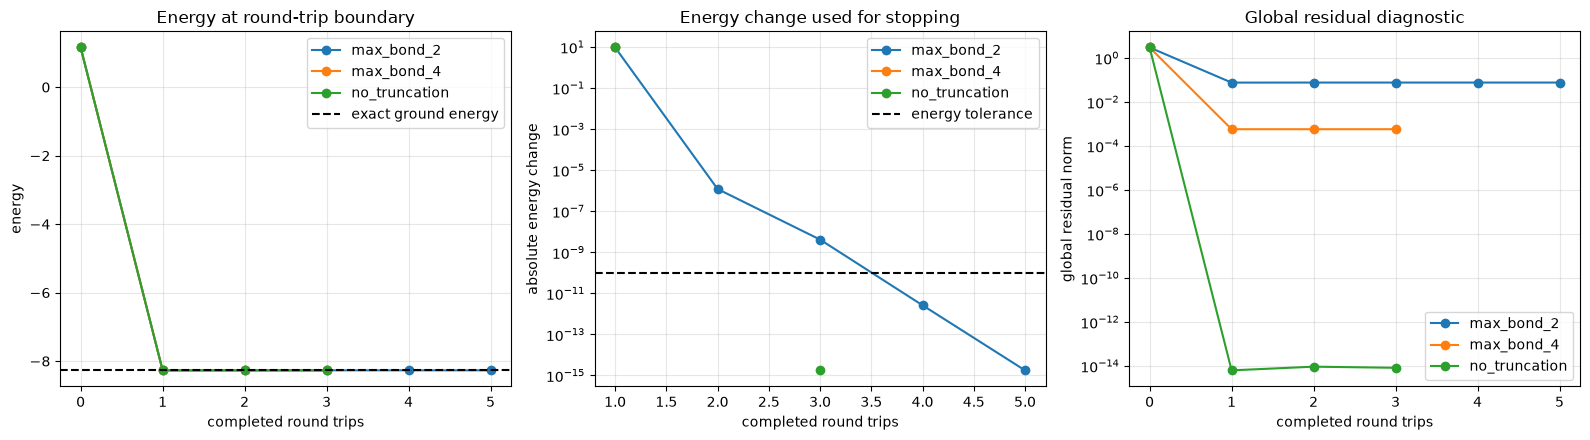

stage 6 - tables and plots: OK


In [15]:
def convergence_results_to_dataframe(
    results: dict[str, DMRGConvergenceResult],
) -> pd.DataFrame:
    """複数条件の往復履歴をlong形式のDataFrameへ変換する。"""
    rows: list[dict[str, object]] = []
    for condition, result in results.items():
        for record in result.history:
            rows.append(
                {
                    "condition": condition,
                    "round_trip": record.round_trip,
                    "energy": record.energy,
                    "energy_change": record.energy_change,
                    "global_residual": record.global_residual,
                    "energy_variance": record.energy_variance,
                    "exact_energy_gap": record.exact_energy_gap,
                    "state_norm_squared": record.state_norm_squared,
                    "actual_bond_dimensions": record.actual_bond_dimensions,
                    "max_discarded_weight": record.max_discarded_weight,
                    "stability_count": record.stability_count,
                    "stop_reason": result.stop_reason,
                }
            )
    return pd.DataFrame(rows)


def summarize_convergence_results(
    results: dict[str, DMRGConvergenceResult],
) -> pd.DataFrame:
    """各条件の最終状態を1行へ要約する。"""
    rows: list[dict[str, object]] = []
    for condition, result in results.items():
        final_record = result.history[-1]
        rows.append(
            {
                "condition": condition,
                "completed_round_trips": final_record.round_trip,
                "stop_reason": result.stop_reason,
                "final_energy": final_record.energy,
                "final_exact_energy_gap": final_record.exact_energy_gap,
                "final_global_residual": final_record.global_residual,
                "final_energy_variance": final_record.energy_variance,
                "final_actual_bond_dimensions": final_record.actual_bond_dimensions,
                "last_round_max_discarded_weight": final_record.max_discarded_weight,
            }
        )
    return pd.DataFrame(rows).sort_values("condition").reset_index(drop=True)


if COMPARISON_RESULTS is not None and len(COMPARISON_RESULTS) == len(BOND_LIMITS):
    HISTORY_DF = convergence_results_to_dataframe(COMPARISON_RESULTS)
    SUMMARY_DF = summarize_convergence_results(COMPARISON_RESULTS)

    display(SUMMARY_DF)

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    for condition, condition_df in HISTORY_DF.groupby("condition", sort=True):
        axes[0].plot(
            condition_df["round_trip"],
            condition_df["energy"],
            marker="o",
            label=condition,
        )
        positive_change = condition_df["energy_change"].where(
            condition_df["energy_change"] > 0.0
        )
        axes[1].plot(
            condition_df["round_trip"],
            positive_change,
            marker="o",
            label=condition,
        )
        positive_residual = condition_df["global_residual"].where(
            condition_df["global_residual"] > 0.0
        )
        axes[2].plot(
            condition_df["round_trip"],
            positive_residual,
            marker="o",
            label=condition,
        )

    axes[0].axhline(
        exact_ground_energy.item(),
        color="black",
        linestyle="--",
        label="exact ground energy",
    )
    axes[0].set_title("Energy at round-trip boundary")
    axes[0].set_xlabel("completed round trips")
    axes[0].set_ylabel("energy")

    axes[1].axhline(
        ENERGY_TOLERANCE,
        color="black",
        linestyle="--",
        label="energy tolerance",
    )
    axes[1].set_yscale("log")
    axes[1].set_title("Energy change used for stopping")
    axes[1].set_xlabel("completed round trips")
    axes[1].set_ylabel("absolute energy change")

    axes[2].set_yscale("log")
    axes[2].set_title("Global residual diagnostic")
    axes[2].set_xlabel("completed round trips")
    axes[2].set_ylabel("global residual norm")

    for axis in axes:
        axis.grid(alpha=0.3)
        axis.legend()

    plt.tight_layout()
    plt.show()
    print("stage 6 - tables and plots: OK")
else:
    HISTORY_DF = SUMMARY_DF = None
    print("stage 6 - tables and plots: SKIP (bond comparison is incomplete)")


## 11. 最終検証

ここでは、数値結果が得られた場合に限り、Notebook全体の契約をまとめて確認する。

- 初期状態をround-trip 0として記録している。
- 初期状態のenergy変化とdiscarded weightは未定義である。
- 全残差ノルムの二乗とenergy分散が一致する。
- dense HamiltonianとMPO縮約のenergyが各往復境界で一致する。
- 正常な終了理由を持つ。
- `converged`は指定したenergy安定条件を満たしたという意味に限定する。

bond上限間の最終energyや残差の単調性は、有限反復の一般的保証ではないためassertしない。


In [16]:
if COMPARISON_RESULTS is not None and len(COMPARISON_RESULTS) == len(BOND_LIMITS):
    for condition, result in COMPARISON_RESULTS.items():
        max_bond = BOND_LIMIT_BY_CONDITION[condition]
        assert result.history[0].round_trip == 0
        assert result.history[0].energy_change is None
        assert result.history[0].max_discarded_weight is None
        assert result.stop_reason in {
            "converged",
            "max_round_trips_reached",
        }
        for record in result.history:
            assert math.isfinite(record.energy)
            assert math.isfinite(record.global_residual)
            assert math.isfinite(record.energy_variance)
            assert math.isfinite(record.exact_energy_gap)
            assert math.isfinite(record.state_norm_squared)
            if max_bond is not None:
                assert all(
                    bond_dimension <= max_bond
                    for bond_dimension in record.actual_bond_dimensions
                )
            assert record.energy_variance >= 0.0
            assert record.exact_energy_gap >= -ATOL
            torch.testing.assert_close(
                torch.tensor(
                    record.global_residual**2,
                    dtype=DTYPE,
                    device=DEVICE,
                ),
                torch.tensor(
                    record.energy_variance,
                    dtype=DTYPE,
                    device=DEVICE,
                ),
                atol=ATOL,
                rtol=RTOL,
            )

    print("final validation: OK")
else:
    print("final validation: SKIP (the exercise TODOs are incomplete)")


final validation: OK


## 12. 考察問題

実行結果を見て、自分の言葉で答える。

1. energyが設定した条件で安定したのに全残差が残る場合、何が言えて、何は言えないか。
2. 同じbond上限で往復を増やしてenergyが改善した場合、どの誤差が減った可能性があるか。何を保証できないか。
3. bond上限を増やしてenergyや全残差が改善した場合、それだけで$E_k-E_\chi^\star$と$E_\chi^\star-E_0$を厳密に分離できるか。
4. 各局所有効Hamiltonianの固有値残差が小さくても、全Hamiltonianに対する残差が小さいとは限らないのはなぜか。
5. 全残差がゼロでも、その状態を基底状態だと断定できないのはなぜか。

## 13. このNotebookで言えること

03の`converged`は、指定した初期状態、bond上限、更新法、許容値のもとで、**往復境界のenergy変化が設定条件を満たした**ことを意味する。

次は別の主張であり、このNotebookの停止理由だけからは保証されない。

- MPS自体が完全に不変になった。
- bond制約内の大域的な最小energyへ到達した。
- 厳密な固有状態へ到達した。
- 厳密基底状態へ到達した。

toy問題では厳密対角化との比較によって追加診断できるが、その厳密解を停止判定へ使用していない点が重要である。
